In [12]:
# Imports

import os
from typing import Literal
from pydantic import BaseModel, Field
from langchain.chat_models import init_chat_model
from langchain_core.messages import HumanMessage, SystemMessage, AIMessage, BaseMessage
from langgraph.graph import StateGraph, START, END, MessagesState
from langgraph.checkpoint.memory import MemorySaver
from dotenv import load_dotenv

In [2]:
# ENV variables
load_dotenv()

GEMINI_API_KEY = os.environ.get("GEMINI_API_KEY")
bool(GEMINI_API_KEY)

True

In [9]:
# ==========================================
# 1. Structured Output Schema for Gemini
# ==========================================
class ReviewAnalysis(BaseModel):
    sentiment: Literal["Positive", "Neutral", "Negative"] = Field(
        description="Classify tone. 1-2 stars or complaints = Negative, 3 stars = Neutral, 4-5 stars = Positive."
    )
    draft_response: str = Field(
        description="A professional, brand-appropriate draft response to the review."
    )

In [5]:
# ==========================================
# 2. Graph State Definition
# ==========================================
class ReviewState(TypedDict):
    review_id: str
    author: str
    rating: int
    review_text: str
    sentiment: Optional[str]
    draft_response: Optional[str]
    feedback: Optional[str]
    status: Literal["PENDING", "APPROVED", "REJECTED", "REPHRASING"]

In [10]:
# ==========================================
# 2. Model Initialization (Gemini)
# ==========================================
llm = init_chat_model(
    model="gemini-3.5-flash-lite",
    model_provider="google_genai",
    temperature=0.3
)
structured_llm = llm.with_structured_output(ReviewAnalysis)

In [13]:
# ==========================================
# 3. LangGraph Node: Process Review (Model Turn)
# ==========================================
def process_review_node(state: MessagesState) -> MessagesState:
    """
    Invokes Gemini with the full conversation history (System prompt, 
    review input, previous AI responses, and user feedback).
    """
    print("\n🤖 [Gemini Agent] Processing conversation state...")
    
    # Invoke structured LLM passing the entire message history
    result: ReviewAnalysis = structured_llm.invoke(state["messages"])
    
    # Format the AI's structured response cleanly for the chat history
    ai_response_text = (
        f"📊 **Sentiment Analysis:** [{result.sentiment}]\n"
        f"✍️ **Draft Response:** {result.draft_response}"
    )
    
    return {
        "messages": [AIMessage(content=ai_response_text)]
    }

In [14]:
# ==========================================
# 4. Conditional Edge Router
# ==========================================
def router_after_human(state: MessagesState) -> Literal["process_review", END]:
    """
    Inspects the last message from the human to decide whether to loop back 
    to Gemini for a refactor or end the workflow.
    """
    last_message = state["messages"][-1].content.strip().upper()
    
    if last_message.startswith("F") or "REFACTOR" in last_message:
        return "process_review" # Loop back for conversation history continuation
    else:
        return END # Terminate on Approve [A] or Reject [R]

In [23]:
# ==========================================
# 5. Build Cyclic Graph Workflow
# ==========================================
workflow = StateGraph(MessagesState)

# Add nodes
workflow.add_node("process_review", process_review_node)

# Define edges
workflow.add_edge(START, "process_review")
workflow.add_conditional_edges(
    "process_review",
    router_after_human,
    {
        "process_review": "process_review",
        END: END
    }
)

# Compile graph with MemorySaver checkpointer for thread persistence
memory = MemorySaver()
app = workflow.compile(checkpointer=memory)

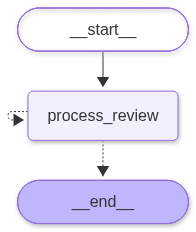

In [24]:
from IPython.display import Image, display

display(Image(app.get_graph().draw_mermaid_png()))

In [25]:
# ==========================================
# 6. Interactive CLI Runner with Conversation Memory
# ==========================================
def run_interactive_review_session():
    print("🚀 Initializing Cyclic LangGraph Review Agent with Gemini...")
    
    config = {"configurable": {"thread_id": "review_session_101"}}
    
    # Initial system prompt & review context injected into state
    system_prompt = SystemMessage(content=(
        "You are an expert customer success manager for local businesses. "
        "Analyze the incoming customer review by combining the star rating and the text. "
        "Classification rules: "
        "- 1 to 2 stars OR angry/complaining text MUST be classified as 'Negative'. "
        "- 3 stars or mixed text MUST be classified as 'Neutral'. "
        "- 4 to 5 stars with praise MUST be classified as 'Positive'. "
        "Craft a professional, empathetic response draft matching the classified sentiment. "
        "Remember all previous feedback and conversation turns when refining drafts."
    ))
    
    review_input = HumanMessage(content=(
        "New Google Review:\n"
        "Author: Ananya Deshmukh\n"
        "Rating: 2/5 Stars\n"
        "Review: The espresso was lukewarm and the seating area was overcrowded."
    ))
    
    # Kick off graph with initial state
    initial_state = {"messages": [system_prompt, review_input]}
    
    # Stream/Invoke graph execution
    current_state = app.invoke(initial_state, config)
    
    while True:
        # Print the latest AI response from message history
        latest_ai_message = current_state["messages"][-1].content
        print("\n" + "="*60)
        print(latest_ai_message)
        print("="*60)
        
        # Human Input Loop
        action = input("Actions -> [A]pprove & Send | [R]eject | [F]actor (Rephrase with comments): ").strip().upper()
        
        if action.startswith("A"):
            print("\n✅ Success! Response approved and published to Google Business Profile.")
            break
        elif action.startswith("R"):
            print("\n❌ Review dropped. No response sent.")
            break
        elif action.startswith("F"):
            feedback = input("💬 Enter your refactoring comments/instructions: ")
            # Append human feedback to the persistent graph state thread
            human_feedback_message = HumanMessage(content=f"REFACTOR REQUEST: {feedback}")
            
            print("🔄 Feeding conversation history back into Gemini...")
            current_state = app.invoke({"messages": [human_feedback_message]}, config)
        else:
            print("⚠️ Invalid choice. Please enter A, R, or F.")

In [26]:
run_interactive_review_session()

🚀 Initializing Cyclic LangGraph Review Agent with Gemini...

🤖 [Gemini Agent] Processing conversation state...


/Users/thetsajeet/Documents/workspace/thetsajeet/review-pulse/.venv/lib/python3.13/site-packages/langchain_google_genai/chat_models.py:3935: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(



📊 **Sentiment Analysis:** [Negative]
✍️ **Draft Response:** Dear Ananya, thank you for sharing your feedback with us. We are truly sorry to hear that your espresso was lukewarm and that the seating area felt overcrowded during your visit. This is certainly not the experience we want for our customers. We are addressing these issues with our team to ensure our coffee is served hot and our space remains comfortable. We hope you will give us another chance in the future to provide you with a much better experience.


Actions -> [A]pprove & Send | [R]eject | [F]actor (Rephrase with comments):  F
💬 Enter your refactoring comments/instructions:  Give me no more than 10 words


🔄 Feeding conversation history back into Gemini...

🤖 [Gemini Agent] Processing conversation state...


/Users/thetsajeet/Documents/workspace/thetsajeet/review-pulse/.venv/lib/python3.13/site-packages/langchain_google_genai/chat_models.py:3935: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


... (3 outputs left out)

/Users/thetsajeet/Documents/workspace/thetsajeet/review-pulse/.venv/lib/python3.13/site-packages/langchain_google_genai/chat_models.py:3935: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(



📊 **Sentiment Analysis:** [Negative]
✍️ **Draft Response:** We are sorry for the lukewarm espresso and crowding. We will check temperatures and improve seating layout.


Actions -> [A]pprove & Send | [R]eject | [F]actor (Rephrase with comments):  A



✅ Success! Response approved and published to Google Business Profile.
